# Lab 4 — Build the Audience, Then Buy It
Name: Vladislav | Group: KM_43

## Setup

In [14]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab4-tv-audiences/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")
survey = pd.read_csv(f"{DATA}/purchase_survey.txt", sep="\t", dtype=str, keep_default_na=False)
survey_layout = pd.read_csv(f"{DATA}/purchase_survey_layout.txt", sep="\t", dtype=str)
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
universe = pd.read_parquet(f"{DATA}/universe.parquet")
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])
survey_layout.columns = survey_layout.columns.str.replace("﻿", "").str.strip()

### Rules and helpers
- **Persons** = R and L records (no H, no S guests); **adults** = persons aged 18+ in `viewer_attributes`.
- **Broadcast day** runs 06:00–05:59; October 1–31, 2024.
- **Audience size** = average over the 31 days of the daily sum of `daily_weights` of the audience's in-tab members.
- **Rating** (average minute) = Σ(weight × minutes viewed) ÷ (telecast minutes × that day's audience size) × 100;
  viewer = average-minute audience Σ(weight × minutes) ÷ telecast minutes. A program's numbers are means over its
  October Prime telecasts.
- **Cost** of a :30 from `rate_card` at the telecast's start, program rows win over time rows (Lab 2).

In [15]:
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
DAYS = pd.date_range("2024-10-01", "2024-10-31")

va = viewer_attributes.merge(attributes, on="attr_id", how="left")
persons = pd.DataFrame({"respondent_id": va.loc[va["attr_id"].isin([101, 102]), "respondent_id"].unique()})
persons["sex"] = persons["respondent_id"].map(va[va["attr_id"].isin([201, 202])].set_index("respondent_id")["attr_name"])
persons["age"] = persons["respondent_id"].map(va[va["attr_id"] == 300].set_index("respondent_id")["value"])
adults = persons[persons["age"] >= 18].reset_index(drop=True)

dw_p = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]


def broadcast_date(ts):
    return (ts - pd.Timedelta(hours=6)).dt.normalize()


def clock_minutes(hhmm):
    hh, mm = hhmm.str.split(":", expand=True).astype(int).T.values
    return hh * 60 + mm - 360


def daily_size(ids):
    return dw_p[dw_p["respondent_id"].isin(ids)].groupby("broadcast_date")["weight"].sum().reindex(DAYS, fill_value=0)


def size(ids):
    return daily_size(ids).mean()


pv = viewings[viewings["resp_type"].isin(["R", "L"])].copy()
pv["d0"] = broadcast_date(pv["start_ts"])
pv["d1"] = broadcast_date(pv["end_ts"] - pd.Timedelta(seconds=1))
pv = pd.concat([pv.assign(bdate=pv["d0"]), pv[pv["d1"] != pv["d0"]].assign(bdate=pv["d1"])])


def person_minutes(tel):
    m = tel[["telecast_id", "network_code", "broadcast_date", "start_ts", "end_ts"]].merge(
        pv[["respondent_id", "network_code", "bdate", "start_ts", "end_ts"]],
        left_on=["network_code", "broadcast_date"], right_on=["network_code", "bdate"], suffixes=("", "_v"))
    m["minutes"] = (m["end_ts_v"].clip(upper=m["end_ts"]) - m["start_ts_v"].clip(lower=m["start_ts"])).dt.total_seconds() / 60
    m = m[m["minutes"] > 0].groupby(["telecast_id", "broadcast_date", "respondent_id"], as_index=False)["minutes"].sum()
    return m.merge(dw_p[["respondent_id", "broadcast_date", "weight"]], on=["respondent_id", "broadcast_date"])


def rate(tel, pm, ids):
    x = pm[pm["respondent_id"].isin(ids)]
    t = tel.set_index("telecast_id")
    viewers = (x["weight"] * x["minutes"]).groupby(x["telecast_id"]).sum().reindex(t.index, fill_value=0) / t["duration_min"]
    return pd.DataFrame({"viewers": viewers, "rating": viewers / t["broadcast_date"].map(daily_size(ids)) * 100})


def price(tel):
    t = tel[["telecast_id", "network_code", "program_name", "start_ts"]].copy()
    prog_rows = rate_card[rate_card["program_name"].notna()]
    t = t.merge(prog_rows[["network_code", "program_name", "cost_30s_usd"]], on=["network_code", "program_name"], how="left")
    time_rows = rate_card[rate_card["program_name"].isna()].copy()
    time_rows["m0"] = clock_minutes(time_rows["start_time"])
    time_rows["m1"] = clock_minutes(time_rows["end_time"])
    time_rows = time_rows.explode("weekdays").rename(columns={"weekdays": "weekday"})
    time_rows["weekday"] = time_rows["weekday"].astype(int)
    shifted = t["start_ts"] - pd.Timedelta(hours=6)
    t["weekday"] = shifted.dt.day_of_week
    t["minute"] = shifted.dt.hour * 60 + shifted.dt.minute
    rest = t[t["cost_30s_usd"].isna()].drop(columns="cost_30s_usd").reset_index().merge(
        time_rows[["network_code", "weekday", "m0", "m1", "cost_30s_usd"]], on=["network_code", "weekday"])
    rest = rest[(rest["m0"] <= rest["minute"]) & (rest["minute"] < rest["m1"])].set_index("index")
    t.loc[rest.index, "cost_30s_usd"] = rest["cost_30s_usd"]
    return t.set_index("telecast_id")["cost_30s_usd"]


print("Persons (R, L):", len(persons))
print("Adults 18+ in the panel:", len(adults))

Persons (R, L): 10216
Adults 18+ in the panel: 8010


## Task 1.0 — Clean the survey file

In [16]:
codes = survey_layout.loc[survey_layout["RECTYPE"] == "B", "KEYWORD"]
YES = ["1", "1.0", "y", "yes", "true"]
NO = ["0", "0.0", "n", "no"]
PAIRS = {"X710101": "1", "X710102": "2", "X710103": "3+"}
BRANDS = {"X710201": "stride", "X710202": "kestrel", "X710203": "easywalk"}

s = survey.copy()
s["rid"] = s["RESPID"].str.strip().str.replace(r"\.0$", "", regex=True)
s["kw"] = s["KEYWORD"].str.strip().str.upper()
s["v"] = s["VALUE"].str.strip().str.lower()
header = s["RESPID"] == "RESPID"
footer = s["RESPID"].str.startswith("TOTAL")
data = s[~header & ~footer].copy()
data["id"] = data["rid"].astype(int)
in_panel = data["id"].isin(persons["respondent_id"])
is_adult = data["id"].isin(adults["respondent_id"])
yes = data["v"].isin(YES)
valid = data["kw"].isin(codes)
clean = data[yes & valid & is_adult]
dups = clean.duplicated(["id", "kw"])
clean = clean[~dups]

pairs = clean[clean["kw"].isin(PAIRS)].sort_values("kw").drop_duplicates("id", keep="last")
two_pairs = clean[clean["kw"].isin(PAIRS)].groupby("id").size().gt(1).sum()
resp = adults[["respondent_id", "sex", "age"]].copy()
resp["buyer"] = resp["respondent_id"].isin(clean["id"])
resp["pairs"] = resp["respondent_id"].map(pairs.set_index("id")["kw"].map(PAIRS)).fillna("0")
for k, b in BRANDS.items():
    resp[b] = resp["respondent_id"].isin(clean.loc[clean["kw"] == k, "id"])
no_any = resp["buyer"] & ~resp["respondent_id"].isin(clean.loc[clean["kw"] == "X710100", "id"])

print("Survey data rows:", len(data))
print("Clean yes answers:", len(clean))
print("Adult panel members:", len(resp))
print("Non-buyers:", (~resp["buyer"]).sum())
print("People with two pair counts:", two_pairs)

bad = pd.DataFrame([
    ("Header line repeated inside the file", header.sum(), "dropped"),
    ("Footer line 'TOTAL ROWS'", footer.sum(), "dropped"),
    ("RESPID with spaces, '.0' or a leading zero", (data["RESPID"] != data["id"].astype(str)).sum(), "fixed: stripped, read as integer"),
    ("KEYWORD in lower case or with spaces", (data["KEYWORD"] != data["kw"]).sum(), "fixed: stripped, upper case"),
    ("VALUE yes written as y / yes / TRUE / 1.0", (yes & (data["VALUE"] != "1")).sum(), "fixed: read as yes"),
    ("VALUE no (0 / 0.0 / N / no)", data["v"].isin(NO).sum(), "dropped: the file lists yes answers only"),
    ("VALUE empty", (data["v"] == "").sum(), "dropped: not a yes"),
    ("KEYWORD not in the layout", (~valid).sum(), "dropped"),
    ("RESPID not a panel person", (~in_panel).sum(), "dropped"),
    ("RESPID of a panel child under 18", (in_panel & ~is_adult).sum(), "dropped"),
    ("Same person and keyword twice (after the fixes)", dups.sum(), "dropped the copies"),
    ("Person with two pair counts", two_pairs, "kept the higher count"),
    ("Buyer without the Any row", no_any.sum(), "counted as a buyer"),
], columns=["Bad record", "Rows", "What I did"])
display(bad)

check = survey_layout.loc[survey_layout["RECTYPE"] == "B", ["KEYWORD", "Text", "SAMPLE"]].set_index("KEYWORD")
mine = {"X710100": resp["buyer"].sum(), **{k: (resp["pairs"] == v).sum() for k, v in PAIRS.items()},
        **{k: resp[b].sum() for k, b in BRANDS.items()},
        **{k: clean.loc[clean["kw"] == k, "id"].nunique() for k in ["X710298", "X710299"]}}
check["My count"] = pd.Series(mine)
check["SAMPLE"] = check["SAMPLE"].astype(int)
check["Difference"] = check["My count"] - check["SAMPLE"]
display(check)

raw_kestrel = survey.loc[survey["KEYWORD"] == "X710202", "RESPID"].nunique()
raw_buyers = survey.loc[survey["KEYWORD"] == "X710100", "RESPID"].nunique()
print("Kestrel buyers, raw / clean (n):", raw_kestrel, "/", resp["kestrel"].sum())
print("Share of buyers, raw / clean:", f"{raw_buyers / len(resp):.3f}", "/", f"{resp['buyer'].mean():.3f}")

Survey data rows: 18346
Clean yes answers: 15510
Adult panel members: 8010
Non-buyers: 3231
People with two pair counts: 113


,Bad record,Rows,What I did
0,Header line repeated inside the file,2,dropped
1,Footer line 'TOTAL ROWS',1,dropped
2,"RESPID with spaces, '.0' or a leading zero",1455,"fixed: stripped, read as integer"
3,KEYWORD in lower case or with spaces,1104,"fixed: stripped, upper case"
4,VALUE yes written as y / yes / TRUE / 1.0,1194,fixed: read as yes
5,VALUE no (0 / 0.0 / N / no),619,dropped: the file lists yes answers only
6,VALUE empty,123,dropped: not a yes
7,KEYWORD not in the layout,738,dropped
8,RESPID not a panel person,150,dropped
9,RESPID of a panel child under 18,273,dropped


,Text,SAMPLE,My count,Difference
KEYWORD,,,,
X710100,Any,4779,4779,0
X710101,1 pair,1810,1810,0
X710102,2 pairs,1308,1308,0
X710103,3 or more pairs,1661,1661,0
X710201,STRIDE,1563,1563,0
X710202,KESTREL,354,354,0
X710203,EASYWALK,1050,1050,0
X710298,OTHER BRAND,2739,2739,0
X710299,DON'T KNOW,371,371,0


Kestrel buyers, raw / clean (n): 495 / 354
Share of buyers, raw / clean: 0.548 / 0.597


**Answer:** The file broke all three promises of the vendor. On top of two header lines repeated in the middle and a 'TOTAL ROWS' footer, 1,455 RESPIDs carry spaces, a '.0' or a leading zero, 1,104 KEYWORDs are lower case or padded, and yes is written six ways (1, 1.0, y, Y, yes, TRUE). 619 rows are 'no' answers and 123 have an empty VALUE although the file should list yes answers only, 738 rows use codes that are not in the layout, 150 RESPIDs are not panel people and 273 belong to children, and after the fixes 933 rows repeat the same person and keyword. 113 people have two pair counts (I kept the higher) and 238 buyers have a pair count or a brand but no Any row (counted as buyers). After cleaning all nine counts match the layout's SAMPLE exactly. Taken as delivered, the file gives 495 Kestrel buyers instead of 354 (40 % too many, mostly duplicates and 'no' rows) and a buyer share of 0.548 instead of 0.597 (the lower-case codes and the buyers without an Any row are lost).

## Task 1.1 — Four definitions

In [17]:
AUD = {
    "Adults 18+": adults["respondent_id"],
    "Shoe buyers": resp.loc[resp["buyer"], "respondent_id"],
    "Heavy buyers": resp.loc[resp["pairs"] == "3+", "respondent_id"],
    "Kestrel buyers": resp.loc[resp["kestrel"], "respondent_id"],
    "Adults 25-54": adults.loc[adults["age"].between(25, 54), "respondent_id"],
}
sizes = pd.Series({a: size(ids) for a, ids in AUD.items()})
print("Adults 18+ (M):", f"{sizes['Adults 18+'] / 1e6:.1f}")
print("Shoe buyers (M):", f"{sizes['Shoe buyers'] / 1e6:.1f}")
print("Heavy buyers, 3+ pairs (M):", f"{sizes['Heavy buyers'] / 1e6:.1f}")
print("Kestrel buyers (M):", f"{sizes['Kestrel buyers'] / 1e6:.1f}")
print("Adults 25-54 (M):", f"{sizes['Adults 25-54'] / 1e6:.1f}")
print("Kestrel buyers in panel (n):", len(AUD["Kestrel buyers"]))
display(pd.DataFrame({"Size (M)": sizes / 1e6, "Share of adults": sizes / sizes["Adults 18+"],
                      "Panel members (n)": {a: len(ids) for a, ids in AUD.items()}}).round(3))

Adults 18+ (M): 252.6
Shoe buyers (M): 148.1
Heavy buyers, 3+ pairs (M): 49.6
Kestrel buyers (M): 10.0
Adults 25-54 (M): 123.7
Kestrel buyers in panel (n): 354


,Size (M),Share of adults,Panel members (n)
Adults 18+,252.553,1.000,8010
Shoe buyers,148.056,0.586,4779
Heavy buyers,49.586,0.196,1661
Kestrel buyers,10.026,0.040,354
Adults 25-54,123.738,0.490,4814


## Task 1.2 — Who are they?

,18-34 men,35-54 men,55+ men,18-34 women,35-54 women,55+ women
Adults 18+,0.144,0.160,0.185,0.144,0.160,0.208
Shoe buyers,0.140,0.158,0.186,0.140,0.178,0.197
Heavy buyers,0.111,0.138,0.189,0.139,0.226,0.196
Kestrel buyers,0.118,0.189,0.126,0.181,0.265,0.121
Adults 25-54,0.174,0.326,0.000,0.174,0.326,0.000


,18-34 men,35-54 men,55+ men,18-34 women,35-54 women,55+ women
Adults 18+,100.0,100.0,100.0,100.0,100.0,100.0
Shoe buyers,97.0,99.0,101.0,98.0,111.0,95.0
Heavy buyers,77.0,87.0,102.0,97.0,142.0,94.0
Kestrel buyers,82.0,119.0,68.0,126.0,166.0,58.0
Adults 25-54,121.0,204.0,0.0,121.0,204.0,0.0


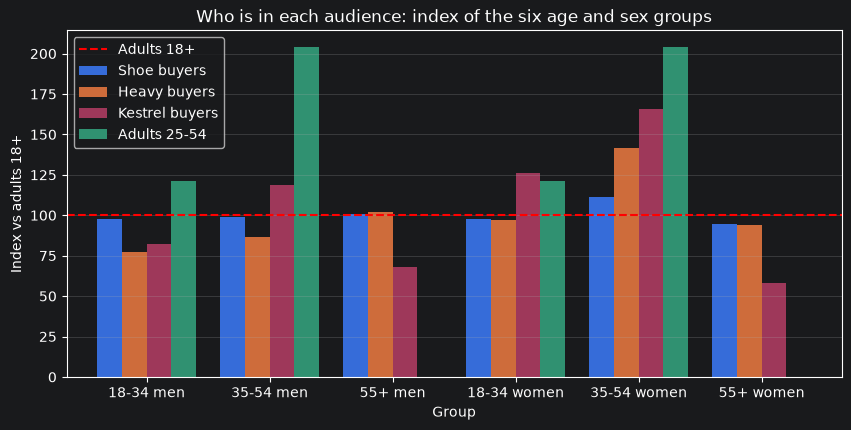

In [18]:
adults["group"] = (pd.cut(adults["age"], [17, 34, 54, 200], labels=["18-34", "35-54", "55+"]).astype(str)
                   + " " + adults["sex"].map({"Male": "men", "Female": "women"}))
GROUPS = [f"{a} {s}" for s in ["men", "women"] for a in ["18-34", "35-54", "55+"]]
share = pd.DataFrame({a: {g: size(adults.loc[adults["respondent_id"].isin(ids) & (adults["group"] == g), "respondent_id"])
                          / sizes[a] for g in GROUPS} for a, ids in AUD.items()}).T
index = share / share.loc["Adults 18+"] * 100
display(share.round(3))
display(index.round(0))

fig, ax = plt.subplots(figsize=(10, 4.5))
index.drop("Adults 18+").T.plot.bar(ax=ax, width=0.8)
ax.axhline(100, color="red", linestyle="--", label="Adults 18+")
ax.set_xlabel("Group")
ax.set_ylabel("Index vs adults 18+")
ax.set_title("Who is in each audience: index of the six age and sex groups")
ax.tick_params(axis="x", rotation=0)
ax.grid(alpha=0.3, axis="y")
ax.legend()
plt.show()

**Answer:** I would hand the planner heavy buyers: 49.6 M people (19.6 % of adults). That is close to what the marketing team asked for, big enough to buy on national TV, and measured on 1,661 panelists. They lean to 35-54 women (index 142) and away from 18-34 men (77). Kestrel buyers (10.0 M, only 354 panelists) are too small and too noisy to rate programs, and they already bought the brand. Adults 25-54 (123.7 M) put the weight in the right ages, but most of them are not heavy buyers, and the demo drops the 55+ heavy buyers (39 % of the audience). "Athletic-shoe buyers" look like all adults because 59 % of adults bought at least one pair, so the group is most of the population and every index is 95-111. A fused attribute cannot tell whether a program's viewers buy more shoes than other people of the same age, sex and income. Buying is attached through demographics only, so a program's index just repeats its demographic profile; real runners who watch a running show would not show up as buyers.

## Task 2.1 — Programs by audience

In [19]:
PROGRAMS = {
    "Sunday Night Football (NBC)": ("NBC", "NFL Football"),
    "Monday Night Football (ABC)": ("ABC", "NFL Football"),
    "Dancing with the Stars (ABC)": ("ABC", "Dancing with the Stars"),
    "NCIS (CBS)": ("CBS", "NCIS"),
    "Hannity (FNC)": ("FNC", "Hannity"),
    "Unsellable Houses (HGTV)": ("HGTV", "Unsellable Houses"),
    "Halloween Wars (FOOD)": ("FOOD", "Halloween Wars"),
    "Grotesquerie (FX)": ("FX", "Grotesquerie"),
}
prime = programs[programs["daypart"] == "Prime"]
tel8 = pd.concat([prime[(prime["network_code"] == n) & (prime["program_name"] == p)].assign(program=k)
                  for k, (n, p) in PROGRAMS.items()], ignore_index=True)
pm8 = person_minutes(tel8)
tel8 = tel8.set_index("telecast_id")
tel8["cost"] = price(tel8.reset_index())
for a in ["Adults 18+", "Heavy buyers", "Kestrel buyers"]:
    r = rate(tel8.reset_index(), pm8, AUD[a])
    tel8[f"rtg {a}"] = r["rating"]
    tel8[f"viewers {a}"] = r["viewers"]

prog = tel8.groupby("program").agg(telecasts=("program", "size"), cost=("cost", "mean"),
                                   **{c: (c, "mean") for c in tel8.columns if c.startswith(("rtg", "viewers"))}).reindex(PROGRAMS)
t21 = pd.DataFrame({
    "Telecasts": prog["telecasts"],
    "Adults rating": prog["rtg Adults 18+"],
    "Target rating": prog["rtg Heavy buyers"],
    "Target viewers (K)": prog["viewers Heavy buyers"] / 1e3,
    "Composition": prog["viewers Heavy buyers"] / prog["viewers Adults 18+"],
    "Index": prog["rtg Heavy buyers"] / prog["rtg Adults 18+"] * 100,
    "Cost per :30 (USD)": prog["cost"],
    "Adults CPM (USD)": prog["cost"] / prog["viewers Adults 18+"] * 1000,
    "Target CPM (USD)": prog["cost"] / prog["viewers Heavy buyers"] * 1000,
})
display(t21.round({"Adults rating": 2, "Target rating": 2, "Target viewers (K)": 0, "Composition": 3, "Index": 0,
                   "Cost per :30 (USD)": 0, "Adults CPM (USD)": 2, "Target CPM (USD)": 2}))
print("Target universe (M):", f"{sizes['Heavy buyers'] / 1e6:.1f}")
print("Heavy buyers share of adults:", f"{sizes['Heavy buyers'] / sizes['Adults 18+']:.3f}")

,Telecasts,Adults rating,Target rating,Target viewers (K),Composition,Index,Cost per :30 (USD),Adults CPM (USD),Target CPM (USD)
program,,,,,,,,,
Sunday Night Football (NBC),4,5.82,5.79,2865.0,0.195,99.0,487200.0,33.12,170.05
Monday Night Football (ABC),3,8.93,8.36,4149.0,0.184,94.0,723600.0,32.09,174.40
Dancing with the Stars (ABC),9,3.25,3.14,1564.0,0.191,97.0,158600.0,19.33,101.39
NCIS (CBS),3,2.21,2.43,1206.0,0.216,110.0,178800.0,32.09,148.22
Hannity (FNC),22,1.09,0.84,417.0,0.152,77.0,39900.0,14.50,95.71
Unsellable Houses (HGTV),13,0.50,0.64,317.0,0.249,127.0,12900.0,10.12,40.66
Halloween Wars (FOOD),9,0.28,0.33,162.0,0.228,116.0,9700.0,13.67,59.90
Grotesquerie (FX),25,0.26,0.25,124.0,0.188,96.0,7592.0,11.50,61.11


Target universe (M): 49.6
Heavy buyers share of adults: 0.196


## Task 2.2 — Index, volume or price?

Highest index (program): Unsellable Houses (HGTV)
Most target viewers (program): Monday Night Football (ABC)
Lowest target CPM (program): Unsellable Houses (HGTV)


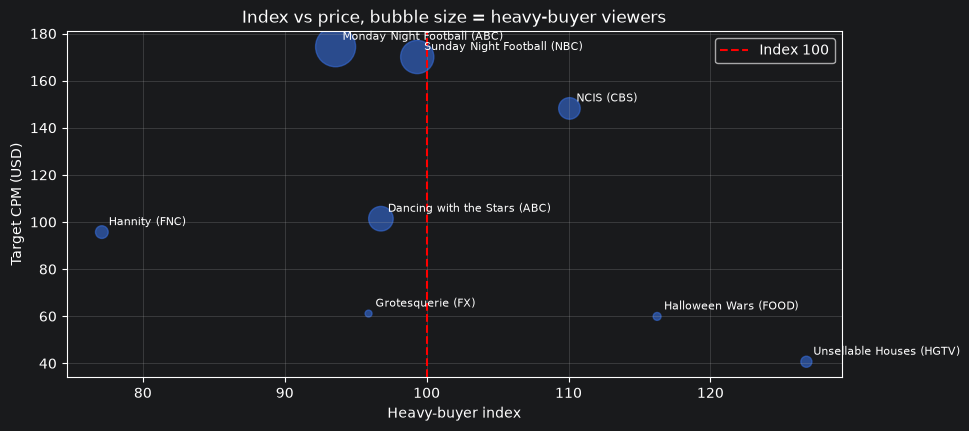

In [20]:
print("Highest index (program):", t21["Index"].idxmax())
print("Most target viewers (program):", t21["Target viewers (K)"].idxmax())
print("Lowest target CPM (program):", t21["Target CPM (USD)"].idxmin())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(t21["Index"], t21["Target CPM (USD)"], s=t21["Target viewers (K)"] / 5, alpha=0.6)
for p, r in t21.iterrows():
    ax.annotate(p, (r["Index"], r["Target CPM (USD)"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.axvline(100, color="red", linestyle="--", label="Index 100")
ax.set_xlabel("Heavy-buyer index")
ax.set_ylabel("Target CPM (USD)")
ax.set_title("Index vs price, bubble size = heavy-buyer viewers")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Answer:** No. Unsellable Houses (HGTV) has the highest index (127) and also the lowest target CPM (USD 40.66), but it delivers only 317 K heavy buyers per telecast, and its rating rests on about 25 heavy-buyer panelists. Monday Night Football (ABC) delivers the most target viewers (4.1 M per telecast), with an index of only 94 and a target CPM of USD 174. To a client who wants "only the highest index" I would say what the shampoo example says: the index measures how concentrated the audience is, not how many target people you get or what they cost. A plan of only the top-index programs is a few small cable shows with a handful of spots, so its reach stays small, while the 94-index programs still put 18-19 % of their viewers on the target. The buy should be judged on target CPM and target impressions, with the index as a tie-breaker.

## Task 2.3 — Kestrel buyers

In [21]:
n_aud = {a: pm8[pm8["respondent_id"].isin(AUD[a])].groupby("telecast_id")["respondent_id"].nunique()
         .reindex(tel8.index, fill_value=0).groupby(tel8["program"]).mean() for a in ["Heavy buyers", "Kestrel buyers"]}
t23 = pd.DataFrame({
    "Heavy-buyer index": t21["Index"],
    "Kestrel index": prog["rtg Kestrel buyers"] / prog["rtg Adults 18+"] * 100,
    "Heavy-buyer panelists per telecast": n_aud["Heavy buyers"].reindex(PROGRAMS),
    "Kestrel panelists per telecast": n_aud["Kestrel buyers"].reindex(PROGRAMS),
})
display(t23.round(1))
print("Spread of the index (std), heavy / Kestrel:", f"{t23['Heavy-buyer index'].std():.1f}", "/",
      f"{t23['Kestrel index'].std():.1f}")
print("Heavy buyers / Kestrel buyers in the panel (n):", len(AUD["Heavy buyers"]), "/", len(AUD["Kestrel buyers"]))

,Heavy-buyer index,Kestrel index,Heavy-buyer panelists per telecast,Kestrel panelists per telecast
program,,,,
Sunday Night Football (NBC),99.3,98.5,329.0,75.2
Monday Night Football (ABC),93.6,85.9,292.7,69.3
Dancing with the Stars (ABC),96.8,82.7,122.6,23.4
NCIS (CBS),110.1,56.5,86.3,11.0
Hannity (FNC),77.1,42.6,15.9,2.1
Unsellable Houses (HGTV),126.8,76.9,25.4,4.0
Halloween Wars (FOOD),116.2,95.2,13.7,2.8
Grotesquerie (FX),95.9,129.6,11.4,3.1


Spread of the index (std), heavy / Kestrel: 15.3 / 26.5
Heavy buyers / Kestrel buyers in the panel (n): 1661 / 354


**Answer:** The Kestrel index runs from 43 (Hannity) to 130 (Grotesquerie), a spread almost twice the heavy-buyer one (std 26.5 vs 15.3). Kestrel buyers are only 354 panelists, so a cable telecast is seen by 2-4 of them, and one person more or less moves the rating by tens of percent. Some of the difference is real: Kestrel skews to 25-54 women and away from 55+, so Hannity and NCIS are low. Most of it, though, is sampling noise. I would trust the heavy-buyer index (1,661 panelists, 11-25 per cable telecast and about 300 for the NFL). Ways to check:
- compute a standard error, or bootstrap the index over panelists;
- compare the October index with other months;
- compute the index that the program's age, sex and income profile predicts. The fusion works only through demographics, so that is the most a fused Kestrel index can mean.

## Task 3.1 — Weights

In [22]:
acr = acr_sessions.copy()
acr["start_ts"] = acr["start_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["end_ts"] = acr["end_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["minutes"] = (acr["end_ts"] - acr["start_ts"]).dt.total_seconds() / 60
acr["bdate"] = broadcast_date(acr["start_ts"])
acr_ok = acr[acr["minutes"] >= 1]
live = acr_ok[acr_ok["session_type"] == "live"]

tvs = acr.groupby("tv_id")["hashed_ip"].first().reset_index()
one_hh = hh_attributes["hashed_ip"].value_counts()
one_hh = one_hh[one_hh == 1].index
matched = tvs[tvs["hashed_ip"].isin(one_hh)].merge(hh_attributes, on="hashed_ip")
matched["head_age"] = np.where(matched["head_age_band"] == "65+", "65+", "Under 65")

intab = acr_ok[["tv_id", "bdate"]].drop_duplicates().merge(matched[["tv_id", "head_age", "income_band"]], on="tv_id")
cell_n = intab.groupby(["bdate", "head_age", "income_band"]).size().rename("n").reset_index()
cell_n = cell_n.merge(universe, on=["head_age", "income_band"])
cell_n["w"] = cell_n["tv_households"] / cell_n["n"]
intab = intab.merge(cell_n[["bdate", "head_age", "income_band", "w"]], on=["bdate", "head_age", "income_band"])
wsum = intab.groupby("bdate")["w"].sum()

print("TVs matched to one household:", len(matched))
print("Weights sum per day (M):", f"{wsum.min() / 1e6:.1f}", "to", f"{wsum.max() / 1e6:.1f}")
print("Universe (M):", f"{universe['tv_households'].sum() / 1e6:.1f}")

cells = matched.groupby(["head_age", "income_band"]).size().rename("matched TVs").reset_index().merge(universe)
cells["footprint share"] = cells["matched TVs"] / cells["matched TVs"].sum()
cells["universe share"] = cells["tv_households"] / cells["tv_households"].sum()
cells["average weight"] = cells.set_index(["head_age", "income_band"]).index.map(
    intab.groupby(["head_age", "income_band"])["w"].mean())
display(cells.round(3))

for name, keys in [("head age only", ["head_age"]), ("income only", ["income_band"])]:
    u = universe.groupby(keys)["tv_households"].sum().reset_index()
    n = intab.groupby(["bdate"] + keys).size().rename("n").reset_index().merge(u, on=keys)
    n[name] = n["tv_households"] / n["n"]
    intab = intab.merge(n[["bdate"] + keys + [name]], on=["bdate"] + keys)

ref = reference_ratings.merge(programs, on="telecast_id")
rows = []
for _, t in ref.iterrows():
    x = live[(live["network_code"] == t["network_code"]) & (live["start_ts"] < t["end_ts"]) & (live["end_ts"] > t["start_ts"])]
    ov = (x["end_ts"].clip(upper=t["end_ts"]) - x["start_ts"].clip(lower=t["start_ts"])).dt.total_seconds() / 60
    watched = ov.groupby(x["tv_id"]).sum().loc[lambda d: d >= 1].index
    day = intab[intab["bdate"] == t["broadcast_date"]]
    rows.append({"telecast": f"{t['program_name']} ({t['network_code']})", "date": f"{t['broadcast_date']:%Y-%m-%d}",
                 "Unweighted": day["tv_id"].isin(watched).mean() * 100,
                 "Weighted": day.loc[day["tv_id"].isin(watched), "w"].sum() / day["w"].sum() * 100,
                 "Reference": t["hh_rating"],
                 **{n: day.loc[day["tv_id"].isin(watched), n].sum() / day[n].sum() * 100 for n in ["head age only", "income only"]}})
t31 = pd.DataFrame(rows).set_index("telecast")
t31["Change"] = t31["Weighted"] - t31["Unweighted"]
display(t31[["date", "Unweighted", "Weighted", "Reference", "Change"]].round(2))
gap_u = (t31["Reference"] - t31["Unweighted"]).mean()
gap_w = (t31["Reference"] - t31["Weighted"]).mean()
print("Mean gap unweighted (points):", f"{gap_u:.2f}")
print("Mean gap weighted (points):", f"{gap_w:.2f}")
print("Share of gap closed:", f"{1 - gap_w / gap_u:.3f}")
for n in ["head age only", "income only"]:
    print(f"Share of gap closed, weights by {n}:", f"{1 - (t31['Reference'] - t31[n]).mean() / gap_u:.3f}")

TVs matched to one household: 19607
Weights sum per day (M): 125.8 to 125.8
Universe (M): 125.8


,head_age,income_band,matched TVs,tv_households,footprint share,universe share,average weight
0,65+,$100k-$150k,695,4914000,0.035,0.039,7268.463
1,65+,$150k+,732,5050000,0.037,0.040,7105.528
2,65+,$25k-$50k,654,7791000,0.033,0.062,12226.656
3,65+,$50k-$75k,610,6059000,0.031,0.048,10237.268
4,65+,$75k-$100k,577,4317000,0.029,0.034,7719.760
5,65+,Under $25k,540,7508000,0.028,0.060,14304.845
6,Under 65,$100k-$150k,3452,17425000,0.176,0.139,5196.728
7,Under 65,$150k+,4465,24389000,0.228,0.194,5625.233
8,Under 65,$25k-$50k,1727,12581000,0.088,0.100,7502.087
9,Under 65,$50k-$75k,2247,13610000,0.115,0.108,6236.989


,date,Unweighted,Weighted,Reference,Change
telecast,,,,,
MLB Postseason (FOX),2024-10-25,17.03,17.76,25.86,0.72
NFL Football (NBC),2024-10-27,22.62,23.75,33.14,1.13
NCIS (CBS),2024-10-14,5.50,5.80,10.56,0.29
Hannity (FNC),2024-10-16,1.04,1.35,2.30,0.31
Unsellable Houses (HGTV),2024-10-16,2.12,2.08,3.69,-0.04
Halloween Baking Championship (FOOD),2024-10-14,0.95,0.90,1.63,-0.05
Grotesquerie (FX),2024-10-16,2.17,2.11,3.53,-0.06
The Real Housewives of New York City (BRAVO),2024-10-15,0.71,0.64,1.23,-0.07


Mean gap unweighted (points): 3.73
Mean gap weighted (points): 3.44
Share of gap closed: 0.075
Share of gap closed, weights by head age only: 0.096
Share of gap closed, weights by income only: -0.019


## Task 3.2 — What weighting cannot fix
**Answer:** Weighting moved the broadcast telecasts up and the cable ones slightly down. NFL (NBC) rose 1.1 points, the MLB postseason (FOX) 0.7, and Hannity and NCIS 0.3 each, while HGTV, Food, FX and Bravo fell by 0.04-0.07. The weights raise the homes the footprint lacks, heads aged 65+ and low incomes (average weight about 12,000-14,000 for 65+ homes under $50k, against about 5,000 for under-65 homes over $100k). Those homes watch broadcast networks and Fox News. Still, only 7.5 % of the gap is closed (3.73 to 3.44 points), because weighting only re-balances the homes that are in the footprint. It cannot fix:
- the one-set problem: a home that watched on another TV counts as not watching;
- viewing that ACR could not recognise;
- TVs with no IP or a shared one, which never get a weight;
- homes with no connected smart TV at all;
- the difference inside a cell between a 65+ home that opted in and one that did not.

Weighting by income barely moves these ratings because, once head age is fixed, viewing of these telecasts hardly differs by income. Income weights alone close -1.9 % of the gap and head-age weights alone 9.6 %. A variable that does not drive viewing cannot correct it.

## Task 4.1 — October predicts October

Telecasts forecast (n): 101
Telecasts skipped, actual 0 (P2+ / heavy buyers): 0 / 0
MAPE, P2+ (%): 35.8
MAPE, heavy buyers (%): 38.6
Biggest miss, P2+ (program, date): Krapopolis (FOX), 2024-10-27


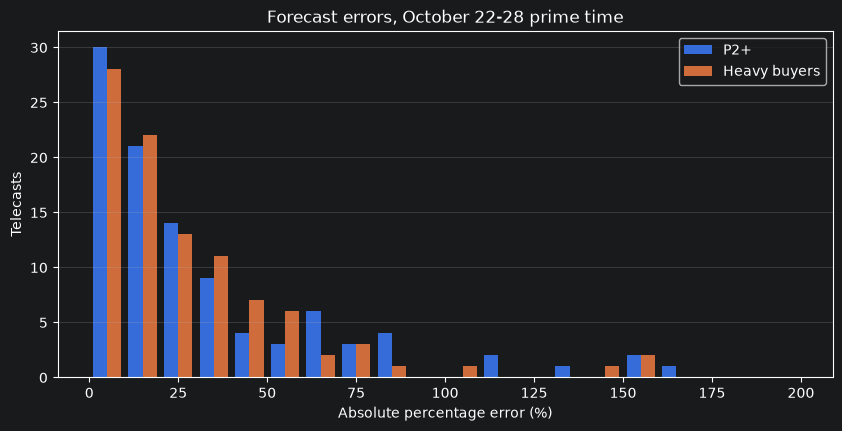

In [23]:
H0, H1, F0, F1 = (pd.Timestamp(d) for d in ["2024-10-01", "2024-10-21", "2024-10-22", "2024-10-28"])
big_prime = programs[(programs["daypart"] == "Prime") & programs["network_code"].isin(BIG)
                     & programs["broadcast_date"].between(H0, F1)].reset_index(drop=True)
pm_big = person_minutes(big_prime)
AUD4 = {"P2+": persons["respondent_id"], "Heavy buyers": AUD["Heavy buyers"]}
for a, ids in AUD4.items():
    big_prime[a] = rate(big_prime, pm_big, ids)["rating"].values

hist = big_prime[big_prime["broadcast_date"] <= H1]
fc = big_prime[big_prime["broadcast_date"] >= F0].copy()
hist_mean = hist.groupby(["network_code", "program_name"])[list(AUD4)].mean()
fc = fc.merge(hist_mean.add_suffix(" forecast").reset_index(), on=["network_code", "program_name"], how="left")
fc = fc[fc["P2+ forecast"].notna()].copy()
fc["program"] = fc["program_name"] + " (" + fc["network_code"] + ")"
for a in AUD4:
    fc[f"{a} APE"] = ((fc[a] - fc[f"{a} forecast"]).abs() / fc[a]).where(fc[a] > 0) * 100
mape = {a: fc[f"{a} APE"].mean() for a in AUD4}
worst = fc.loc[fc["P2+ APE"].idxmax()]
print("Telecasts forecast (n):", len(fc))
print("Telecasts skipped, actual 0 (P2+ / heavy buyers):", (fc["P2+"] == 0).sum(), "/", (fc["Heavy buyers"] == 0).sum())
print("MAPE, P2+ (%):", f"{mape['P2+']:.1f}")
print("MAPE, heavy buyers (%):", f"{mape['Heavy buyers']:.1f}")
print("Biggest miss, P2+ (program, date):", f"{worst['program']}, {worst['broadcast_date']:%Y-%m-%d}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist([fc["P2+ APE"].dropna(), fc["Heavy buyers APE"].dropna()], bins=np.arange(0, 201, 10), label=list(AUD4))
ax.set_xlabel("Absolute percentage error (%)")
ax.set_ylabel("Telecasts")
ax.set_title("Forecast errors, October 22-28 prime time")
ax.grid(alpha=0.3, axis="y")
ax.legend()
plt.show()

## Task 4.2 — Why it missed

In [24]:
miss = fc.nlargest(5, "P2+ APE")
display(miss.assign(date=miss["broadcast_date"].dt.strftime("%Y-%m-%d"), start=miss["start_ts"].dt.strftime("%H:%M"))
        [["program", "episode_name", "date", "start", "duration_min", "P2+ forecast", "P2+", "P2+ APE"]]
        .rename(columns={"P2+ forecast": "Forecast", "P2+": "Actual", "P2+ APE": "Error (%)"}).round(2))
around = programs[programs.set_index(["network_code", "broadcast_date"]).index.isin(
    miss.set_index(["network_code", "broadcast_date"]).index) & (programs["daypart"].isin(["Prime", "Prime Access", "Late Night"]))]
display(around.assign(date=around["broadcast_date"].dt.strftime("%Y-%m-%d"),
                      start=around["start_ts"].dt.strftime("%H:%M"), end=around["end_ts"].dt.strftime("%H:%M"))
        [["network_code", "date", "start", "end", "program_name", "episode_name", "is_repeat"]])
print("Heavy-buyer panelists per forecast telecast, median:",
      pm_big[pm_big["respondent_id"].isin(AUD["Heavy buyers"]) & pm_big["telecast_id"].isin(fc["telecast_id"])]
      .groupby("telecast_id")["respondent_id"].nunique().reindex(fc["telecast_id"], fill_value=0).median())
print("P2+ panelists per forecast telecast, median:",
      pm_big[pm_big["telecast_id"].isin(fc["telecast_id"])].groupby("telecast_id")["respondent_id"].nunique()
      .reindex(fc["telecast_id"], fill_value=0).median())

,program,episode_name,date,start,duration_min,Forecast,Actual,Error (%)
81,Krapopolis (FOX),Mr. Boogens,2024-10-27,21:30,30,1.06,0.22,387.76
79,Universal Basic Guys (FOX),Fight or Flight,2024-10-27,20:30,30,0.68,0.26,162.17
38,Fire Country (CBS),NaN,2024-10-27,22:44,16,1.70,0.67,154.76
66,Accused (FOX),Marcus' Story,2024-10-22,21:00,60,0.95,0.37,154.63
5,What Would You Do? (ABC),Episode 11,2024-10-23,22:00,60,0.44,0.18,138.13


,network_code,date,start,end,program_name,episode_name,is_repeat
309,ABC,2024-10-23,19:00,20:00,Local / Syndicated Programming,NaN,False
310,ABC,2024-10-23,20:00,21:30,The Golden Bachelorette,Week 6,False
311,ABC,2024-10-23,21:30,22:00,Abbott Elementary,Class Pet,False
312,ABC,2024-10-23,22:00,23:00,What Would You Do?,Episode 11,False
313,ABC,2024-10-23,23:00,00:35,Local / Syndicated Programming,NaN,False
314,ABC,2024-10-23,00:35,01:05,Nightline,Episode 212,False
1539,CBS,2024-10-27,19:35,20:00,60 Minutes,Deportation | Sanctions | Surfmen,False
1540,CBS,2024-10-27,20:00,20:30,Poppa's House,NaN,True
1541,CBS,2024-10-27,20:30,20:44,Fire Country,NaN,True
1542,CBS,2024-10-27,20:44,21:44,Tracker,Bloodlines,False


Heavy-buyer panelists per forecast telecast, median: 46.0
P2+ panelists per forecast telecast, median: 241.0


**Answer:** The five biggest misses are small telecasts whose slot or lead-in changed.
- **Krapopolis (388 %) and Universal Basic Guys (162 %), FOX, October 27.** Their new Sunday episodes in the history (October 6 and 20) followed a national late NFL game (KC @ SF on October 20), which is a huge lead-in. On October 27 FOX had only regional games, and NBC had Cowboys at 49ers on Sunday Night Football.
- **Fire Country (CBS), October 27.** The NFL game ran to 19:35 and pushed the schedule. A repeat of Fire Country was split into 14- and 16-minute pieces at 20:30 and 22:44, instead of its usual Friday 21:00 original.
- **What Would You Do? (ABC), October 23.** One history telecast (October 7) aired on Monday after Dancing with the Stars. That inflates the history mean against its Wednesday slot after The Golden Bachelorette.
- **Accused (FOX), October 22.** Same slot, but the rating is only 0.4, so a few panelists more or less give a large percentage error.

The heavy-buyer forecast is less accurate (MAPE 38.6 % vs 35.8 %) because the median telecast is seen by only 46 heavy-buyer panelists, against 241 persons. Both the actual and the history are noisier. A better forecast would use:
1. the schedule context: time slot, day, the lead-in and competing events (NFL overruns, Sunday Night Football, World Series games), and new episodes vs repeats;
2. more history, with the target rating shrunk toward the program's P2+ rating times its usual composition instead of a raw mean of a few noisy target ratings.

## Task 5.1 — The plan

In [25]:
BUDGET = 1_000_000
MAX_PER_TELECAST = 2
week = tel8[tel8["broadcast_date"].between("2024-10-14", "2024-10-20")].groupby("program").size()
plan = t21[["Index", "Cost per :30 (USD)", "Target viewers (K)", "Target CPM (USD)", "Composition"]].copy()
plan["telecasts per week"] = week
plan["spots"] = 0
left = BUDGET
for on_target in [True, False]:
    for p in plan[(plan["Index"] >= 90) == on_target].sort_values("Target CPM (USD)").index:
        n = int(min(plan.loc[p, "telecasts per week"] * MAX_PER_TELECAST, left // plan.loc[p, "Cost per :30 (USD)"]))
        plan.loc[p, "spots"] = n
        left -= n * plan.loc[p, "Cost per :30 (USD)"]
plan = plan[plan["spots"] > 0].sort_values("Target CPM (USD)")
plan["cost"] = plan["spots"] * plan["Cost per :30 (USD)"]
plan["target impressions (M)"] = plan["spots"] * plan["Target viewers (K)"] / 1e3
plan["adult impressions (M)"] = plan["target impressions (M)"] / plan["Composition"]
display(plan.round(2))
print("Plan cost ($):", f"{plan['cost'].sum():.0f}")
print("Plan target impressions (M):", f"{plan['target impressions (M)'].sum():.1f}")
print("Plan target CPM (USD):", f"{plan['cost'].sum() / plan['target impressions (M)'].sum() / 1e3:.2f}")
print("Share of adult impressions on heavy buyers:", f"{plan['target impressions (M)'].sum() / plan['adult impressions (M)'].sum():.3f}")

,Index,Cost per :30 (USD),Target viewers (K),Target CPM (USD),Composition,telecasts per week,spots,cost,target impressions (M),adult impressions (M)
program,,,,,,,,,,
Unsellable Houses (HGTV),126.77,12900.0,317.25,40.66,0.25,2,4,51600.0,1.27,5.10
Halloween Wars (FOOD),116.24,9700.0,161.93,59.90,0.23,1,2,19400.0,0.32,1.42
Grotesquerie (FX),95.91,7592.0,124.24,61.11,0.19,5,10,75920.0,1.24,6.60
Hannity (FNC),77.11,39900.0,416.88,95.71,0.15,5,4,159600.0,1.67,11.01
Dancing with the Stars (ABC),96.78,158600.0,1564.23,101.39,0.19,1,2,317200.0,3.13,16.41
NCIS (CBS),110.06,178800.0,1206.34,148.22,0.22,1,2,357600.0,2.41,11.14


Plan cost ($): 981320
Plan target impressions (M): 10.0
Plan target CPM (USD): 97.70
Share of adult impressions on heavy buyers: 0.194


## Task 5.2 — Recommendation
**Answer:** For the USD 1,000,000 week I would buy 24 :30s for USD 981,320, which delivers about 10.0 M heavy-buyer impressions at a target CPM of USD 97.70. The spots are:
- 2 in Dancing with the Stars (ABC) and 2 in NCIS (CBS);
- 4 in Unsellable Houses (HGTV), 2 in Halloween Wars (Food) and 10 in Grotesquerie (FX);
- 4 in Hannity (FNC), with the money that was left.

I bought by target CPM among programs with an index of 90+, at most two spots per telecast in a normal week. Cheap high-index cable comes first, then DWTS and NCIS for volume. Hannity is cheap per target viewer but under-indexes (77), so it only fills the rest. I left out the NFL: at a USD 170-174 target CPM and USD 0.5-0.7 M per spot, one game would take most of the budget for 3-4 M impressions. The delivery is not certain. In Task 4 a single telecast's heavy-buyer rating missed by 39 % on average, and the cable numbers rest on 11-25 panelists, so I would ask for a guarantee with make-goods and plan on ±25 % for the week. Only 19.4 % of the impressions reach heavy buyers, so about 80 % of the money (roughly USD 790 K) pays for adults who are not the target. That is unavoidable on TV, where no program is more than 25 % heavy buyers. After the week I would run a post-buy:
- heavy-buyer and adult ratings of the telecasts that actually aired, against the plan;
- delivered target impressions, reach and frequency, and whether make-goods are owed;
- if possible, Kestrel sales or site visits among heavy buyers.